# Credit Card Fraud Detection
**An end-to-end machine learning project on a heavily imbalanced dataset**

*Author: Aishwarya Markandu*

---

## Why this project

Fraud is a needle in a haystack: roughly **1 transaction in 600** is fraudulent.
A "model" that approves every single payment would be right 99.8% of the time and would
stop **zero** fraud. So the real questions are not about accuracy:

1. How do we train a model when the interesting class is almost invisible?
2. Which metrics tell the truth when accuracy lies?
3. Where should the alert threshold sit, given that a missed fraud and a false alarm do not cost the same?
4. Can we explain a decision that will land on a real customer's card?

## Data

[Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) (Kaggle, ULB Machine Learning Group):
card transactions made by European cardholders over two days in September 2013.
`V1`–`V28` are PCA components (anonymised for confidentiality); `Time` is the number of seconds since the first
transaction, `Amount` is the transaction amount and `Class` is the label (1 = fraud).

## Roadmap

`1` Cleaning → `2` Exploratory analysis → `3` Feature engineering & preparation → `4` Modelling →
`5` Evaluation (metrics, thresholds, explainability) → `6` Export for the web report

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

RESULTS = Path("results")
FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Colour roles (same logic as the web report): legit = neutral grey, fraud = red,
# models = blue / orange / aqua.
C_LEGIT, C_FRAUD = "#8a8f98", "#e34948"
C_MODEL = {"logreg": "#2a78d6", "rf": "#eb6834", "xgb": "#1baf7a", "baseline": "#898781"}
sns.set_theme(style="whitegrid", context="notebook", rc={
    "axes.spines.top": False, "axes.spines.right": False, "grid.color": "#e1e0d9",
    "axes.edgecolor": "#c3c2b7", "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

OUT = {}  # everything the web report needs is collected here and exported at the end


def clean(o):
    """Make numpy / pandas objects JSON-serialisable and keep the file light."""
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, np.ndarray):
        return clean(o.tolist())
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else round(float(o), 5)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return o

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Loading and cleaning the data

The notebook first looks for `data/creditcard.csv`. If it is not there, it downloads the dataset with `kagglehub`
(this requires Kaggle credentials on your machine the first time).

In [2]:
DATA = Path("data/creditcard.csv")
if not DATA.exists():
    import kagglehub
    DATA = Path(kagglehub.dataset_download("mlg-ulb/creditcardfraud")) / "creditcard.csv"

raw = pd.read_csv(DATA)
print(f"Raw table: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
raw.head()

Raw table: 284,807 rows × 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


**Two integrity checks before anything else:**
* missing values;
* exact duplicate rows. If the same transaction sits in both the training and the test set, the test score is
  inflated by memorisation, so duplicates are removed *before* splitting.

In [3]:
n_raw = len(raw)
n_missing = int(raw.isna().sum().sum())
dup_mask = raw.duplicated()
n_dup = int(dup_mask.sum())
n_dup_fraud = int(raw.loc[dup_mask, "Class"].sum())
fraud_raw = int(raw["Class"].sum())

df = raw.drop_duplicates().reset_index(drop=True)
n_clean = len(df)
n_fraud = int(df["Class"].sum())
fraud_rate = n_fraud / n_clean

print(f"Missing values        : {n_missing}")
print(f"Duplicate rows        : {n_dup:,}  (of which {n_dup_fraud} fraudulent)")
print(f"Rows after cleaning   : {n_clean:,}")
print(f"Frauds after cleaning : {n_fraud}  → {fraud_rate:.4%}  (1 in {round(1 / fraud_rate):,})")

OUT["data"] = dict(rows_raw=n_raw, rows_clean=n_clean, missing=n_missing, duplicates=n_dup,
                   duplicate_frauds=n_dup_fraud, fraud_raw=fraud_raw, fraud_clean=n_fraud,
                   legit_clean=n_clean - n_fraud, fraud_rate=fraud_rate, one_in=round(1 / fraud_rate),
                   hours_span=float(df["Time"].max() / 3600), total_fraud_amount=float(df.loc[df.Class == 1, "Amount"].sum()))

Missing values        : 0
Duplicate rows        : 1,081  (of which 19 fraudulent)
Rows after cleaning   : 283,726
Frauds after cleaning : 473  → 0.1667%  (1 in 600)


## 2. Exploratory data analysis

### 2.1 How imbalanced is it?

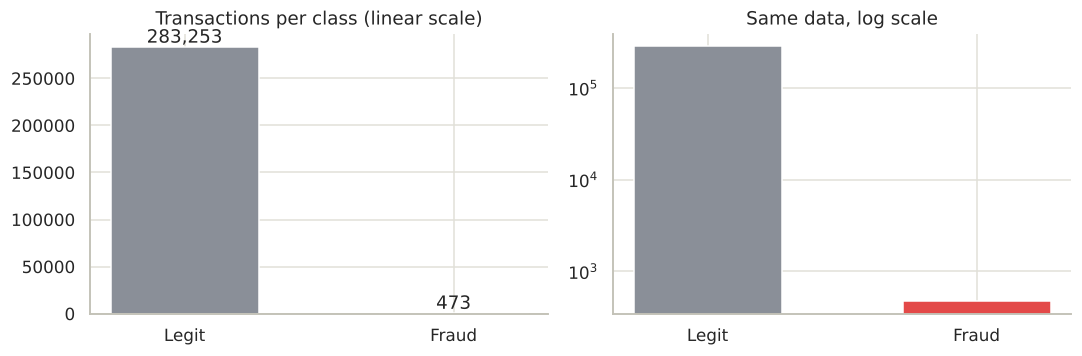

'Approve everything' accuracy: 99.8333%   |   fraud caught: 0 of 473


In [4]:
counts = df["Class"].value_counts().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(["Legit", "Fraud"], counts.values, color=[C_LEGIT, C_FRAUD], width=0.55)
ax[0].set_title("Transactions per class (linear scale)")
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
ax[1].bar(["Legit", "Fraud"], counts.values, color=[C_LEGIT, C_FRAUD], width=0.55)
ax[1].set_yscale("log")
ax[1].set_title("Same data, log scale")
plt.tight_layout()
plt.savefig(FIG / "eda_class_balance.png")
plt.show()

# What a model that never raises an alert would score
naive_acc = counts[0] / counts.sum()
print(f"'Approve everything' accuracy: {naive_acc:.4%}   |   fraud caught: 0 of {n_fraud}")

### 2.2 Transaction amounts: fraud vs legit

Amounts are heavily right-skewed, so I look at them on a log scale.

       median    mean     p90  share_le_1
legit   22.00   88.41  203.00        0.11
fraud    9.82  123.87  348.65        0.36


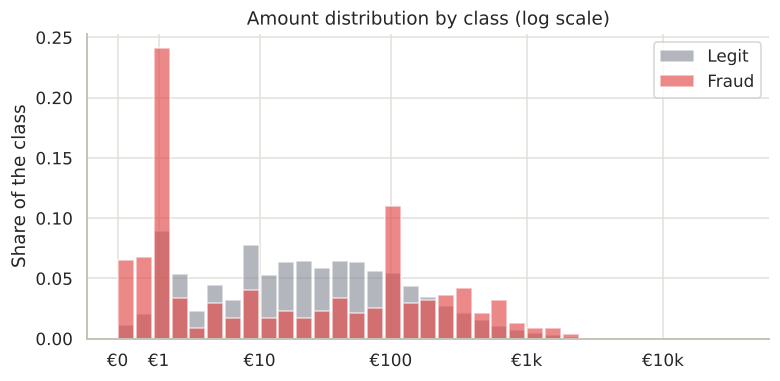

In [5]:
amt = df.groupby("Class")["Amount"]
amount_stats = {
    "legit": dict(median=amt.median()[0], mean=amt.mean()[0], p90=amt.quantile(.9)[0],
                  share_le_1=float((df.loc[df.Class == 0, "Amount"] <= 1).mean())),
    "fraud": dict(median=amt.median()[1], mean=amt.mean()[1], p90=amt.quantile(.9)[1],
                  share_le_1=float((df.loc[df.Class == 1, "Amount"] <= 1).mean())),
}
print(pd.DataFrame(amount_stats).round(2).T)

edges = np.linspace(0, 10.5, 36)
h0, _ = np.histogram(np.log1p(df.loc[df.Class == 0, "Amount"]), bins=edges)
h1, _ = np.histogram(np.log1p(df.loc[df.Class == 1, "Amount"]), bins=edges)
h0, h1 = h0 / h0.sum(), h1 / h1.sum()

fig, ax = plt.subplots(figsize=(8, 3.6))
mid = (edges[:-1] + edges[1:]) / 2
w = edges[1] - edges[0]
ax.bar(mid, h0, width=w * 0.9, color=C_LEGIT, alpha=.65, label="Legit")
ax.bar(mid, h1, width=w * 0.9, color=C_FRAUD, alpha=.65, label="Fraud")
ticks = np.log1p([0, 1, 10, 100, 1000, 10000])
ax.set_xticks(ticks, ["€0", "€1", "€10", "€100", "€1k", "€10k"])
ax.set_ylabel("Share of the class")
ax.set_title("Amount distribution by class (log scale)")
ax.legend()
plt.savefig(FIG / "eda_amount.png")
plt.show()

OUT["eda"] = dict(amount_stats=amount_stats,
                  amount_hist=dict(edges_log=edges, legit=h0, fraud=h1))

### 2.3 When does fraud happen?

`Time` is the number of seconds since the first transaction of the dataset. The data spans ~48 hours, so
`(Time // 3600) % 24` gives an "hour of the day" that stacks the two days on top of each other.
The dataset does not document the clock time of the first transaction; the overnight dip in legit volume
suggests it starts close to midnight, so I treat this as a **proxy** for the hour of day.

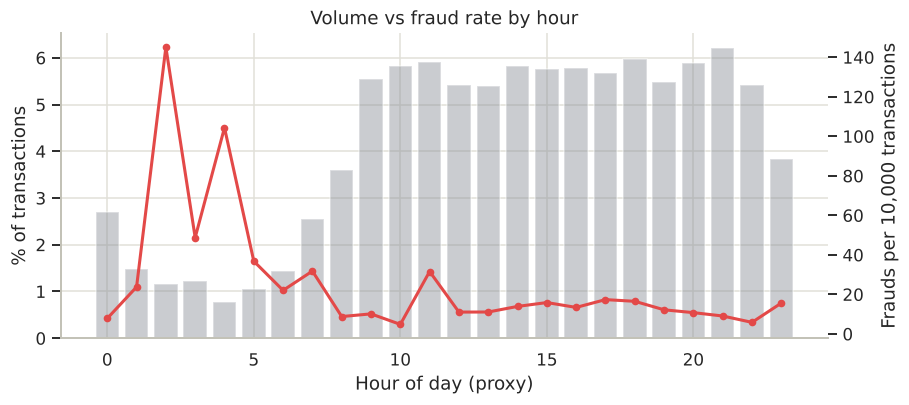

         n  fraud  rate_per_10k
hour                           
2     3308     48         145.1
4     2204     23         104.4
3     3487     17          48.8
5     2988     11          36.8
7     7233     23          31.8


In [6]:
hourly = (df.assign(hour=(df["Time"] // 3600 % 24).astype(int))
            .groupby("hour").agg(n=("Class", "size"), fraud=("Class", "sum")))
hourly["rate_per_10k"] = hourly["fraud"] / hourly["n"] * 1e4

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(hourly.index, hourly["n"] / hourly["n"].sum() * 100, color=C_LEGIT, alpha=.45, label="Share of all transactions (%)")
ax.set_ylabel("% of transactions")
ax2 = ax.twinx()
ax2.plot(hourly.index, hourly["rate_per_10k"], color=C_FRAUD, lw=2, marker="o", ms=4, label="Fraud rate per 10,000")
ax2.set_ylabel("Frauds per 10,000 transactions")
ax2.grid(False)
ax.set_xlabel("Hour of day (proxy)")
ax.set_title("Volume vs fraud rate by hour")
plt.savefig(FIG / "eda_hourly.png")
plt.show()
print(hourly.sort_values("rate_per_10k", ascending=False).head(5).round(1))
OUT["eda"]["hourly"] = hourly.reset_index().to_dict("records")

### 2.4 Which features separate fraud from legit?

V17   -0.313
V14   -0.293
V12   -0.251
V10   -0.207
V16   -0.187
V3    -0.182
V7    -0.172
V11    0.149
V4     0.129
V18   -0.105
V1    -0.094
V9    -0.094
Name: Class, dtype: float64


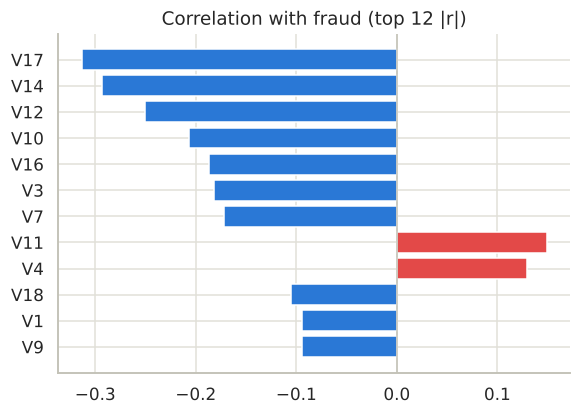

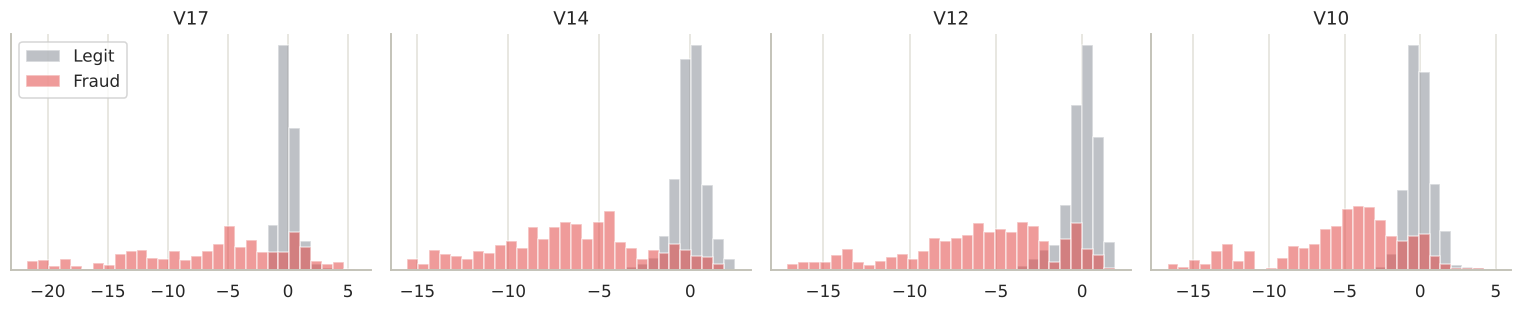

In [7]:
feat_cols = [c for c in df.columns if c not in ("Class",)]
corr = df[feat_cols + ["Class"]].corr()["Class"].drop("Class")
top_corr = corr.reindex(corr.abs().sort_values(ascending=False).index).head(12)
print(top_corr.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(top_corr.index[::-1], top_corr.values[::-1], color=[C_FRAUD if v > 0 else C_MODEL["logreg"] for v in top_corr.values[::-1]])
ax.axvline(0, color="#c3c2b7", lw=1)
ax.set_title("Correlation with fraud (top 12 |r|)")
plt.savefig(FIG / "eda_correlation.png")
plt.show()

# Class separation on the four most correlated features
top4 = list(top_corr.index[:4])
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
dist_out = []
for ax, f in zip(axes, top4):
    v_f, v_l = df.loc[df.Class == 1, f], df.loc[df.Class == 0, f]
    # display range wide enough to include the bulk of BOTH classes (fraud values are often extreme)
    lo = min(v_f.quantile(.02), v_l.quantile(.005))
    hi = max(v_f.quantile(.98), v_l.quantile(.995))
    e = np.linspace(lo, hi, 31)
    ax.hist(v_l, bins=e, density=True, alpha=.55, color=C_LEGIT, label="Legit")
    ax.hist(v_f, bins=e, density=True, alpha=.55, color=C_FRAUD, label="Fraud")
    ax.set_title(f)
    ax.set_yticks([])
    a0, _ = np.histogram(v_l, bins=e)
    a1, _ = np.histogram(v_f, bins=e)
    dist_out.append(dict(feature=f, edges=e, legit=a0 / len(v_l), fraud=a1 / len(v_f)))
axes[0].legend()
plt.tight_layout()
plt.savefig(FIG / "eda_separation.png")
plt.show()

OUT["eda"]["corr"] = [dict(feature=k, r=v) for k, v in top_corr.items()]
OUT["eda"]["dists"] = dist_out

**What the EDA tells me**
* The imbalance is extreme, so everything downstream (split, CV, metrics) must be stratified and imbalance-aware.
* Fraud amounts are *not* larger on average than legit ones — a large share of them are tiny.
* A handful of PCA components (`V17`, `V14`, `V12`, `V10`…) already separate the classes visibly, which is
  promising for a model, but the overlap is real: no single feature does the job.

## 3. Feature engineering and preparation

* `log_amount = log(1 + Amount)` to tame the skew;
* `hour` derived from `Time` (see 2.3); the raw `Time` (an elapsed counter that means nothing in production) is dropped;
* **stratified** 80/20 train/test split, so both sets keep the same fraud rate;
* **robust scaling fitted on the training data only**, wrapped inside a scikit-learn `Pipeline`
  so that it is re-fitted inside every cross-validation fold (no leakage from the validation fold).

In [8]:
X = df.drop(columns="Class").copy()
y = df["Class"].copy()
amount = df["Amount"].copy()

X["log_amount"] = np.log1p(X["Amount"])
X["hour"] = (X["Time"] // 3600 % 24).astype(int)
X = X.drop(columns=["Time", "Amount"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
amount_train, amount_test = amount.loc[X_train.index].values, amount.loc[X_test.index].values

print(f"Train: {len(X_train):,} rows, {y_train.sum()} frauds ({y_train.mean():.4%})")
print(f"Test : {len(X_test):,} rows, {y_test.sum()} frauds ({y_test.mean():.4%})")

SCALE_COLS = ["log_amount", "hour"]


def make_prep():
    return ColumnTransformer([("scale", RobustScaler(), SCALE_COLS)], remainder="passthrough",
                             verbose_feature_names_out=False).set_output(transform="pandas")


spw = float((y_train == 0).sum() / (y_train == 1).sum())  # negatives per positive
print(f"Negatives per positive in train: {spw:.0f}")

OUT["split"] = dict(n_train=len(X_train), n_test=len(X_test), fraud_train=int(y_train.sum()),
                    fraud_test=int(y_test.sum()), n_features=X.shape[1], seed=SEED, neg_per_pos=spw,
                    test_fraud_amount=float(amount_test[y_test.values == 1].sum()))

Train: 226,980 rows, 378 frauds (0.1665%)
Test : 56,746 rows, 95 frauds (0.1674%)
Negatives per positive in train: 599


## 4. Modelling

### 4.1 Four contenders, one fair comparison

| Model | Role | How it handles imbalance |
|---|---|---|
| **Baseline** (always "legit") | The bar to beat — what "doing nothing" scores | – |
| **Logistic Regression** | Simple, linear, interpretable | `class_weight="balanced"` |
| **Random Forest** | Non-linear, bagged trees | `class_weight="balanced_subsample"` |
| **XGBoost** | Non-linear, boosted trees | `scale_pos_weight` |

First pass: sensible default settings, scored by **5-fold stratified cross-validation on the training set only**.
The metric that drives every decision is **PR-AUC** (average precision): it only cares about how well the
rare class is ranked, whereas accuracy and ROC-AUC are flattered by the huge pile of easy negatives.

In [9]:
NAMES = {"baseline": "Baseline", "logreg": "Logistic Regression", "rf": "Random Forest", "xgb": "XGBoost"}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)


def pipe(clf):
    return Pipeline([("prep", make_prep()), ("clf", clf)])


base_models = {
    "baseline": DummyClassifier(strategy="prior"),
    "logreg": LogisticRegression(class_weight="balanced", max_iter=2000),
    "rf": RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=3, max_samples=0.3,
                                 class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "xgb": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                         scale_pos_weight=spw, tree_method="hist", eval_metric="aucpr", n_jobs=-1, random_state=SEED),
}

cv_out = {}
t0 = time.time()
for key, clf in base_models.items():
    s = cross_validate(pipe(clf), X_train, y_train, cv=cv5, scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"})
    cv_out[key] = dict(pr_auc_mean=s["test_pr_auc"].mean(), pr_auc_std=s["test_pr_auc"].std(),
                       roc_auc_mean=s["test_roc_auc"].mean(), folds=s["test_pr_auc"])
    print(f"{NAMES[key]:<20} PR-AUC = {cv_out[key]['pr_auc_mean']:.3f} ± {cv_out[key]['pr_auc_std']:.3f}   "
          f"ROC-AUC = {cv_out[key]['roc_auc_mean']:.3f}")
print(f"({time.time() - t0:.0f}s)")
OUT["cv_default"] = cv_out

Baseline             PR-AUC = 0.002 ± 0.000   ROC-AUC = 0.500


Logistic Regression  PR-AUC = 0.756 ± 0.027   ROC-AUC = 0.981


Random Forest        PR-AUC = 0.821 ± 0.035   ROC-AUC = 0.964


XGBoost              PR-AUC = 0.854 ± 0.027   ROC-AUC = 0.984
(109s)


### 4.2 Hyperparameter tuning (randomized search)

Each model gets its own randomized search, scored on PR-AUC with 3-fold stratified CV on the training set
(same folds for every model). The XGBoost search also explores **how hard to up-weight the fraud class**
(`scale_pos_weight`), since "fully balanced" is a choice, not a law.

In [10]:
spaces = {
    "logreg": (dict(clf__C=loguniform(1e-3, 1e2)), 8),
    "rf": (dict(clf__n_estimators=[100, 200, 300], clf__max_depth=[8, 12, 16, 20],
                clf__min_samples_leaf=[1, 2, 3, 5, 10], clf__max_features=["sqrt", "log2", 0.25],
                clf__max_samples=[0.2, 0.3, 0.4]), 12),
    "xgb": (dict(clf__n_estimators=randint(200, 600), clf__max_depth=randint(3, 9),
                 clf__learning_rate=loguniform(0.02, 0.3), clf__subsample=uniform(0.6, 0.4),
                 clf__colsample_bytree=uniform(0.5, 0.5), clf__min_child_weight=randint(1, 10),
                 clf__gamma=uniform(0, 2), clf__reg_lambda=loguniform(0.5, 10),
                 clf__scale_pos_weight=[1, 10, 25, spw]), 24),
}

searches, tune_out = {}, {}
for key, (space, n_iter) in spaces.items():
    t0 = time.time()
    rs = RandomizedSearchCV(pipe(clone(base_models[key])), space, n_iter=n_iter, scoring="average_precision",
                            cv=cv3, random_state=SEED, n_jobs=1, refit=True)
    rs.fit(X_train, y_train)
    searches[key] = rs
    params = {k.replace("clf__", ""): (float(v) if isinstance(v, (np.floating, float)) else
                                       int(v) if isinstance(v, (np.integer,)) else v)
              for k, v in rs.best_params_.items()}
    tune_out[key] = dict(best_cv_pr_auc=rs.best_score_, n_iter=n_iter, best_params=params)
    print(f"{NAMES[key]:<20} best CV PR-AUC = {rs.best_score_:.3f}   ({n_iter} configs, {time.time() - t0:.0f}s)")
    print("   ", params)
OUT["tuning"] = tune_out

Logistic Regression  best CV PR-AUC = 0.755   (8 configs, 17s)
    {'C': 56.69849511478853}


Random Forest        best CV PR-AUC = 0.822   (12 configs, 634s)
    {'n_estimators': 200, 'min_samples_leaf': 2, 'max_samples': 0.3, 'max_features': 'log2', 'max_depth': 20}


XGBoost              best CV PR-AUC = 0.852   (24 configs, 264s)
    {'colsample_bytree': 0.5079831261101071, 'gamma': 0.461787651244298, 'learning_rate': 0.03841474365667243, 'max_depth': 6, 'min_child_weight': 7, 'n_estimators': 463, 'reg_lambda': 0.5542561258655851, 'scale_pos_weight': 10, 'subsample': 0.7564242430292963}


### 4.3 The final model is chosen on cross-validation — not on the test set

The test set is opened only once the choice is made.

In [11]:
final_key = max(searches, key=lambda k: searches[k].best_score_)
final_est = searches[final_key].best_estimator_
print(f"Selected model (best CV PR-AUC): {NAMES[final_key]}")

Selected model (best CV PR-AUC): XGBoost


## 5. Evaluation on the held-out test set

### 5.1 Why accuracy is the wrong yardstick
Every model is scored at the default 0.5 probability cut-off first. Look at the baseline row.

In [12]:
tuned = {k: s.best_estimator_ for k, s in searches.items()}
proba_test = {"baseline": np.full(len(y_test), y_train.mean())}
for k, est in tuned.items():
    proba_test[k] = est.predict_proba(X_test)[:, 1]

rng = np.random.default_rng(SEED)
B = 300
boot_idx = [rng.integers(0, len(y_test), len(y_test)) for _ in range(B)]
yt = y_test.values


def boot_ci(p):
    vals = []
    for idx in boot_idx:
        if yt[idx].sum() == 0:
            continue
        vals.append(average_precision_score(yt[idx], p[idx]))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


def at_threshold(p, thr):
    pred = (p >= thr).astype(int)
    tn = int(((pred == 0) & (yt == 0)).sum()); fp = int(((pred == 1) & (yt == 0)).sum())
    fn = int(((pred == 0) & (yt == 1)).sum()); tp = int(((pred == 1) & (yt == 1)).sum())
    return dict(tn=tn, fp=fp, fn=fn, tp=tp, accuracy=accuracy_score(yt, pred),
                precision=precision_score(yt, pred, zero_division=0), recall=recall_score(yt, pred),
                f1=f1_score(yt, pred, zero_division=0))


test_out, rows = {}, []
for k in ["baseline", "logreg", "rf", "xgb"]:
    p = proba_test[k]
    m = at_threshold(p if k != "baseline" else np.zeros(len(yt)), 0.5)
    m.update(pr_auc=average_precision_score(yt, p), roc_auc=roc_auc_score(yt, p))
    m["pr_auc_ci"] = boot_ci(p) if k != "baseline" else (m["pr_auc"], m["pr_auc"])
    test_out[k] = m
    rows.append(dict(model=NAMES[k], accuracy=m["accuracy"], precision=m["precision"], recall=m["recall"], f1=m["f1"],
                     pr_auc=m["pr_auc"], ci_low=m["pr_auc_ci"][0], ci_high=m["pr_auc_ci"][1], roc_auc=m["roc_auc"]))
summary = pd.DataFrame(rows).set_index("model")
display(summary.round(3))
OUT["test_at_0.5"] = test_out

,accuracy,precision,recall,f1,pr_auc,ci_low,ci_high,roc_auc
model,,,,,,,,
Baseline,0.998,0.000,0.000,0.000,0.002,0.002,0.002,0.500
Logistic Regression,0.975,0.055,0.874,0.103,0.674,0.574,0.791,0.962
Random Forest,0.999,0.944,0.705,0.807,0.801,0.726,0.887,0.942
XGBoost,1.000,0.973,0.747,0.845,0.820,0.756,0.900,0.978


### 5.2 Precision–recall curves

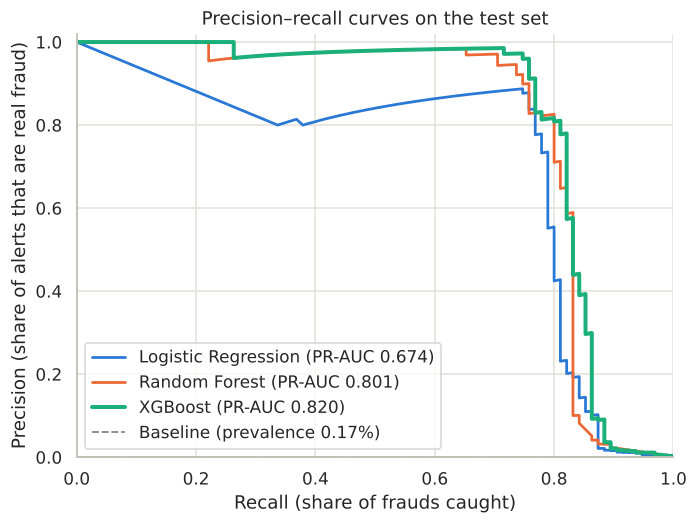

In [13]:
pr_curves = {}
fig, ax = plt.subplots(figsize=(7, 5))
for k in ["logreg", "rf", "xgb"]:
    prec, rec, _ = precision_recall_curve(yt, proba_test[k])
    keep = np.r_[True, np.diff(rec) != 0]
    pr_curves[k] = dict(recall=rec[keep], precision=prec[keep])
    ax.plot(rec, prec, color=C_MODEL[k], lw=2.6 if k == final_key else 1.8,
            label=f"{NAMES[k]} (PR-AUC {test_out[k]['pr_auc']:.3f})")
ax.axhline(yt.mean(), color=C_MODEL["baseline"], ls="--", lw=1.2, label=f"Baseline (prevalence {yt.mean():.2%})")
ax.set_xlabel("Recall (share of frauds caught)")
ax.set_ylabel("Precision (share of alerts that are real fraud)")
ax.set_ylim(0, 1.02); ax.set_xlim(0, 1)
ax.set_title("Precision–recall curves on the test set")
ax.legend(loc="lower left")
plt.savefig(FIG / "pr_curves.png")
plt.show()
OUT["pr_curves"] = pr_curves
OUT["prevalence_test"] = float(yt.mean())

### 5.3 The threshold is a business decision

A fraud model outputs a *probability*. Where we cut it decides who gets blocked:

* **Lower the threshold** → more frauds caught, but more legitimate customers get an alert (review cost, friction).
* **Raise it** → fewer false alarms, but more fraud slips through.

I compare three cut-offs, **all chosen on out-of-fold predictions of the training set** so the test set stays untouched:

1. the default **0.5**;
2. the **F1-optimal** threshold (equal weight on precision and recall);
3. a **cost-based** threshold: a missed fraud costs the transaction amount; a false alarm costs a fixed
   review/friction fee. *The fee below (€5) is an assumption, not a measured number* — the web report lets you move it.

In [14]:
FP_COST = 5.0  # € per false alarm (assumption)
oof = cross_val_predict(clone(final_est), X_train, y_train, cv=cv5, method="predict_proba")[:, 1]
ytr = y_train.values

GRID = np.unique(np.round(np.r_[[0.001, 0.002, 0.005], np.arange(0.01, 1.0, 0.01), [0.995, 0.999]], 4))


def sweep(y_true, p, amt, grid):
    pos = y_true == 1
    rec = {"t": [], "tp": [], "fp": [], "fn": [], "missed": []}
    for t in grid:
        pred = p >= t
        rec["t"].append(float(t))
        rec["tp"].append(int((pred & pos).sum())); rec["fp"].append(int((pred & ~pos).sum()))
        rec["fn"].append(int((~pred & pos).sum())); rec["missed"].append(float(amt[~pred & pos].sum()))
    return {k: np.array(v) for k, v in rec.items()}


sw_oof, sw_test = sweep(ytr, oof, amount_train, GRID), sweep(yt, proba_test[final_key], amount_test, GRID)


def f1_curve(s):
    return 2 * s["tp"] / np.maximum(2 * s["tp"] + s["fp"] + s["fn"], 1)


def plateau_pick(values, best):
    ok = np.where(np.isclose(values, best, atol=1e-12))[0]
    return int(ok[len(ok) // 2])  # middle of the plateau = more stable than its edge


f1_o = f1_curve(sw_oof)
cost_o = sw_oof["missed"] + FP_COST * sw_oof["fp"]
i_f1 = plateau_pick(f1_o, f1_o.max())
i_cost = plateau_pick(cost_o, cost_o.min())
thr = {"default": 0.5, "f1": float(GRID[i_f1]), "cost": float(GRID[i_cost])}
print("Thresholds chosen on out-of-fold training predictions:", {k: round(v, 3) for k, v in thr.items()})

Thresholds chosen on out-of-fold training predictions: {'default': 0.5, 'f1': 0.44, 'cost': 0.5}


,threshold,tp,fp,fn,precision,recall,f1,missed_amount,alerts_per_100k,total_cost
default,0.50,71.0,2.0,24.0,0.973,0.747,0.845,4051.53,128.643,4061.53
f1,0.44,71.0,2.0,24.0,0.973,0.747,0.845,4051.53,128.643,4061.53
cost,0.50,71.0,2.0,24.0,0.973,0.747,0.845,4051.53,128.643,4061.53


Cost with no model at all (every fraud goes through): €14,766


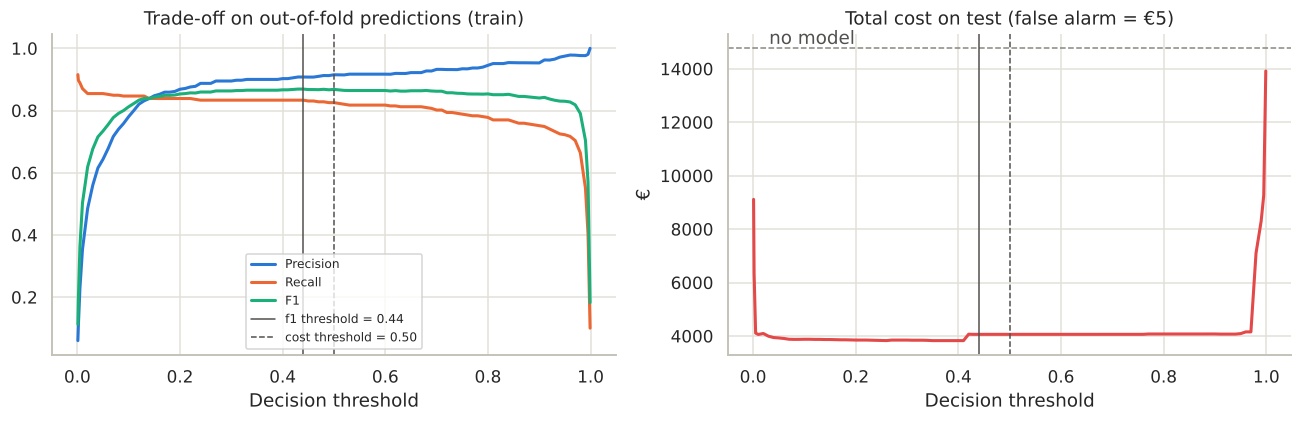

In [15]:
p_fin = proba_test[final_key]
total_fraud_amt = float(amount_test[yt == 1].sum())
ops = {}
for name, t in thr.items():
    m = at_threshold(p_fin, t)
    pred = p_fin >= t
    m["threshold"] = t
    m["missed_amount"] = float(amount_test[(~pred) & (yt == 1)].sum())
    m["caught_amount"] = total_fraud_amt - m["missed_amount"]
    m["alerts_per_100k"] = float(pred.mean() * 1e5)
    m["total_cost"] = m["missed_amount"] + FP_COST * m["fp"]
    ops[name] = m
ops_df = pd.DataFrame(ops).T[["threshold", "tp", "fp", "fn", "precision", "recall", "f1", "missed_amount", "alerts_per_100k", "total_cost"]]
display(ops_df.round(3))
print(f"Cost with no model at all (every fraud goes through): €{total_fraud_amt:,.0f}")

OUT["final"] = dict(key=final_key, name=NAMES[final_key], thresholds=thr, operating_points=ops,
                    fp_cost_assumption=FP_COST, test_fraud_amount=total_fraud_amt)
OUT["sweep"] = dict(grid=GRID, oof={k: v for k, v in sw_oof.items() if k != "t"},
                    test={k: v for k, v in sw_test.items() if k != "t"},
                    n_oof=len(ytr), n_test=len(yt), fraud_oof=int(ytr.sum()), fraud_test=int(yt.sum()),
                    fraud_amount_oof=float(amount_train[ytr == 1].sum()), fraud_amount_test=total_fraud_amt)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
prec_o = sw_oof["tp"] / np.maximum(sw_oof["tp"] + sw_oof["fp"], 1)
rec_o = sw_oof["tp"] / (sw_oof["tp"] + sw_oof["fn"])
ax[0].plot(GRID, prec_o, label="Precision", color=C_MODEL["logreg"], lw=2)
ax[0].plot(GRID, rec_o, label="Recall", color=C_MODEL["rf"], lw=2)
ax[0].plot(GRID, f1_o, label="F1", color=C_MODEL["xgb"], lw=2)
for nm, ls in [("f1", "-"), ("cost", "--")]:
    ax[0].axvline(thr[nm], color="#52514e", ls=ls, lw=1, label=f"{nm} threshold = {thr[nm]:.2f}")
ax[0].set_xlabel("Decision threshold"); ax[0].set_title("Trade-off on out-of-fold predictions (train)")
ax[0].legend(fontsize=8)
ax[1].plot(GRID, sw_test["missed"] + FP_COST * sw_test["fp"], color=C_FRAUD, lw=2)
ax[1].axhline(total_fraud_amt, color="#898781", ls="--", lw=1)
ax[1].text(0.02, total_fraud_amt, " no model", va="bottom", color="#52514e")
for nm in ("f1", "cost"):
    ax[1].axvline(thr[nm], color="#52514e", lw=1, ls="-" if nm == "f1" else "--")
ax[1].set_xlabel("Decision threshold"); ax[1].set_ylabel("€"); ax[1].set_title(f"Total cost on test (false alarm = €{FP_COST:.0f})")
plt.tight_layout()
plt.savefig(FIG / "threshold_tradeoff.png")
plt.show()

#### How sensitive is the best threshold to the cost of a false alarm?

The €5 above is a guess, so I check how the cost-optimal threshold (always picked on out-of-fold training
predictions, then evaluated on the test set) moves when that cost changes.

In [16]:
j_def = int(np.argmin(np.abs(GRID - 0.5)))
sens_rows = []
for c in [1, 2, 5, 10, 25, 50, 100]:
    cost_c = sw_oof["missed"] + c * sw_oof["fp"]
    i = plateau_pick(cost_c, cost_c.min())
    sens_rows.append(dict(fa_cost=c, threshold=GRID[i], frauds_caught=int(sw_test["tp"][i]), false_alarms=int(sw_test["fp"][i]),
                          total_cost=sw_test["missed"][i] + c * sw_test["fp"][i],
                          cost_at_0_5=sw_test["missed"][j_def] + c * sw_test["fp"][j_def]))
sens = pd.DataFrame(sens_rows).set_index("fa_cost")
display(sens.round(3))
OUT["cost_sensitivity"] = sens_rows

,threshold,frauds_caught,false_alarms,total_cost,cost_at_0_5
fa_cost,,,,,
1,0.005,82,302,2900.55,4053.53
2,0.010,81,147,3615.76,4055.53
5,0.500,71,2,4061.53,4061.53
10,0.500,71,2,4071.53,4071.53
25,0.660,71,2,4101.53,4101.53
50,0.660,71,2,4151.53,4151.53
100,0.710,70,2,4252.21,4251.53


### 5.4 Confusion matrices at the three operating points

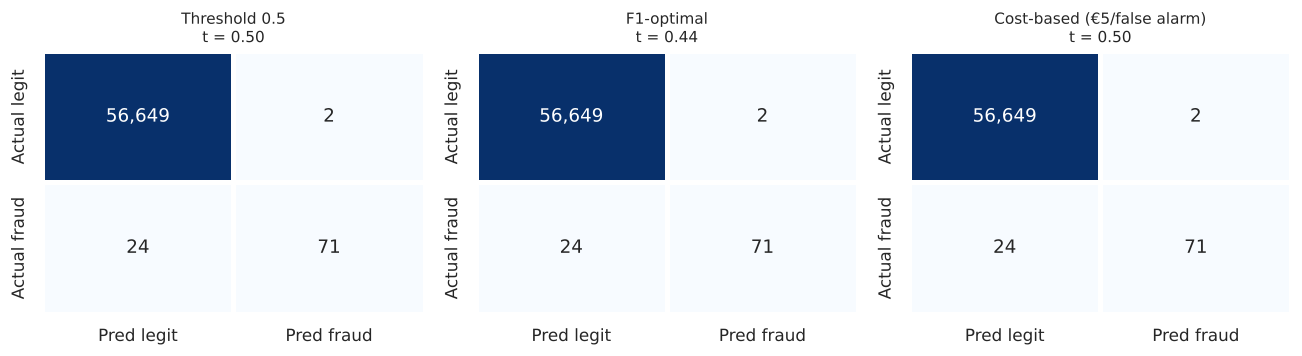

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (nm, title) in zip(axes, [("default", "Threshold 0.5"), ("f1", "F1-optimal"), ("cost", f"Cost-based (€{FP_COST:.0f}/false alarm)")]):
    m = ops[nm]
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax, xticklabels=["Pred legit", "Pred fraud"],
                yticklabels=["Actual legit", "Actual fraud"], linewidths=2, linecolor="white")
    ax.set_title(f"{title}\nt = {m['threshold']:.2f}", fontsize=10)
plt.tight_layout()
plt.savefig(FIG / "confusion_matrices.png")
plt.show()

### 5.5 Feature importance and SHAP explanations

Two complementary views of the final model:
* the model's **native importance** (how much each feature helped build the trees);
* **SHAP** values: for every transaction, how much each feature pushed the fraud score up or down.

SHAP is computed on a *sample of the test set* — all the frauds plus a random batch of legit transactions
(which is why frauds are over-represented in the plots below).

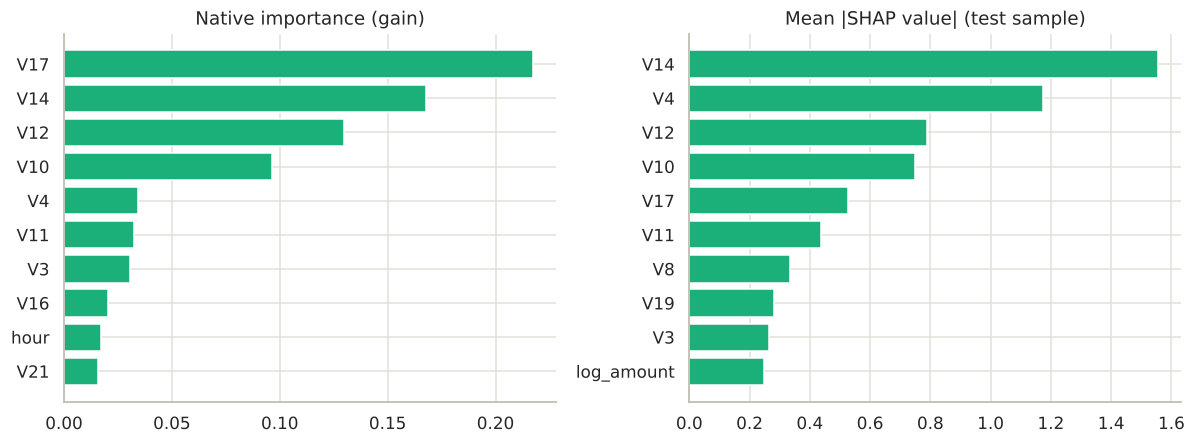

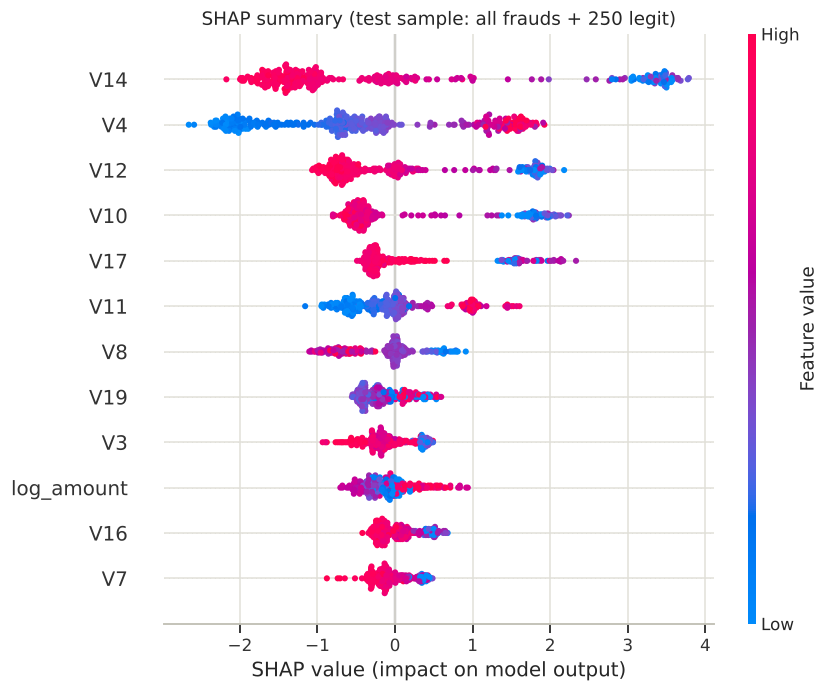

In [18]:
clf = final_est.named_steps["clf"]
Xt_all = final_est.named_steps["prep"].transform(X_test)
fnames = list(Xt_all.columns)

imp_type = "gain" if final_key == "xgb" else "mean decrease in impurity"
native = pd.Series(clf.feature_importances_, index=fnames).sort_values(ascending=False)

rs_ = np.random.default_rng(SEED)
fraud_idx = np.where(yt == 1)[0]
legit_idx = rs_.choice(np.where(yt == 0)[0], size=250, replace=False)
sample_idx = np.r_[fraud_idx, legit_idx]
Xs = Xt_all.iloc[sample_idx]

explainer = shap.TreeExplainer(clf)
sv = explainer(Xs)
shap_vals = sv.values[..., 1] if sv.values.ndim == 3 else sv.values
mean_abs = pd.Series(np.abs(shap_vals).mean(0), index=fnames).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].barh(native.index[:10][::-1], native.values[:10][::-1], color=C_MODEL[final_key])
ax[0].set_title(f"Native importance ({imp_type})")
ax[1].barh(mean_abs.index[:10][::-1], mean_abs.values[:10][::-1], color=C_MODEL[final_key])
ax[1].set_title("Mean |SHAP value| (test sample)")
plt.tight_layout(); plt.savefig(FIG / "importance.png"); plt.show()

shap.summary_plot(shap_vals, Xs, max_display=12, show=False)
plt.title("SHAP summary (test sample: all frauds + 250 legit)")
plt.savefig(FIG / "shap_summary.png"); plt.show()

### 5.6 Why was *this* transaction flagged?

Three individual decisions at the cost-based threshold: a typical true positive, the most confident false
alarm and the missed fraud that scored highest. Reminder: `V1`–`V28` are anonymised PCA components, so SHAP can
tell me *which* component drove the score but not *what it means* in business terms. In production the same
analysis would run on the raw, named features.

In [19]:
t_cost = thr["cost"]
pred_c = p_fin >= t_cost
tp_i = np.where(pred_c & (yt == 1))[0]
fp_i = np.where(pred_c & (yt == 0))[0]
fn_i = np.where(~pred_c & (yt == 1))[0]
picks = {
    "true_positive": tp_i[np.argsort(p_fin[tp_i])[len(tp_i) // 2]],
    "false_alarm": fp_i[np.argmax(p_fin[fp_i])] if len(fp_i) else None,
    "missed_fraud": fn_i[np.argmax(p_fin[fn_i])] if len(fn_i) else None,
}
cases = []
for kind, i in picks.items():
    if i is None:
        continue
    row = Xt_all.iloc[[i]]
    s = explainer(row)
    v = s.values[0, :, 1] if s.values.ndim == 3 else s.values[0]
    order = np.argsort(-np.abs(v))[:6]
    raw_row = X_test.iloc[i]
    cases.append(dict(kind=kind, probability=float(p_fin[i]), amount=float(amount_test[i]), hour=int(raw_row["hour"]),
                      actual=int(yt[i]),
                      contributions=[dict(feature=fnames[j], shap=float(v[j]), value=float(raw_row[fnames[j]])) for j in order]))
    print(f"{kind:<14} p={p_fin[i]:.3f}  amount=€{amount_test[i]:.2f}  top drivers: " +
          ", ".join(f"{fnames[j]} ({v[j]:+.1f})" for j in order[:4]))
OUT["cases"] = cases

# Beeswarm data for the web report (top 10 features)
top10 = list(mean_abs.index[:10])
bee = dict(features=top10, shap=[], value=[], is_fraud=(yt[sample_idx]).tolist(),
           mean_abs=[float(mean_abs[f]) for f in top10])
for f in top10:
    j = fnames.index(f)
    vals = Xs[f].values
    lo, hi = np.percentile(vals, [5, 95])
    norm = np.clip((vals - lo) / (hi - lo) if hi > lo else vals * 0, 0, 1)
    bee["shap"].append(shap_vals[:, j]); bee["value"].append(norm)
OUT["importance"] = dict(native_type=imp_type, native=[dict(feature=k, value=v) for k, v in native.head(12).items()],
                         shap=[dict(feature=k, value=v) for k, v in mean_abs.head(12).items()],
                         sample=dict(n=len(sample_idx), frauds=len(fraud_idx), legit=len(legit_idx)))
OUT["beeswarm"] = bee

true_positive  p=0.997  amount=€1.00  top drivers: V14 (+3.4), V10 (+2.0), V4 (+1.8), V12 (+1.7)
false_alarm    p=0.998  amount=€109.90  top drivers: V14 (+3.5), V10 (+1.8), V12 (+1.8), V17 (+1.5)
missed_fraud   p=0.412  amount=€239.93  top drivers: V17 (+2.2), V12 (+1.8), V4 (+1.1), V3 (-0.9)


## 6. Export for the web report

Everything the bilingual HTML report needs is saved in `results/metrics.json`.

In [20]:
OUT["meta"] = dict(seed=SEED, models=NAMES, final=final_key)
with open(RESULTS / "metrics.json", "w") as fh:
    json.dump(clean(OUT), fh, separators=(",", ":"))
print("Saved", RESULTS / "metrics.json", f"({(RESULTS / 'metrics.json').stat().st_size / 1024:.0f} KB)")

Saved results/metrics.json (74 KB)


## Key takeaways

* **Accuracy rewards doing nothing.** The "approve everything" baseline scores ~99.8% and catches no fraud;
  PR-AUC, precision and recall expose it immediately.
* **Non-linear models earn their keep.** Tree ensembles rank frauds clearly better than the linear model
  (see the PR curves and the table in 5.1).
* **The threshold is a business choice.** The cost-sensitivity table shows it: when a false alarm costs about €1 the
  cost-optimal threshold collapses to ~0.005 (more frauds caught, far more alerts), whereas from about €5 upwards a wide
  plateau of thresholds behaves almost identically. The right cut-off depends on what a false alarm and a missed fraud
  cost *your* business.
* **Explainability is part of the product.** When a decision affects a real customer, "the model said so"
  is not enough — and anonymised features show why production systems need interpretable inputs.

## Limitations and next steps

* The test set holds only ~95 frauds, so every metric carries real uncertainty (see the bootstrap intervals).
* Random split on two days of data: **time-based validation** would mimic production more closely.
* **Resampling** (e.g. SMOTE) as an alternative to class weights.
* **Probability calibration**, so that scores can be read as true probabilities and thresholds transfer between periods.